# Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset

In [5]:
# Step 1: Load the data
trans = pd.read_csv(r"Customer_Transactions.csv")
cust = pd.read_csv(r"Customer_Master_Data.csv")

trans.shape, cust.shape

((23050, 3), (1000, 9))

# Checking Data Structure and Overview

In [6]:
# Check shape , structure and preview
print(f'Shape transaction df: {trans.shape}')
trans.info()
trans.head()


Shape transaction df: (23050, 3)
<class 'pandas.DataFrame'>
RangeIndex: 23050 entries, 0 to 23049
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         23050 non-null  str    
 1   TransactionDate    23050 non-null  str    
 2   TransactionAmount  23050 non-null  float64
dtypes: float64(1), str(2)
memory usage: 540.4 KB


,CustomerID,TransactionDate,TransactionAmount
0,CUST10771,7/31/23,2383.07
1,CUST10100,3/10/24,497.54
2,CUST10031,2/17/25,536.78
3,CUST10987,7/17/23,314.89
4,CUST10831,12/15/24,2543.19


In [7]:
# Checking shae, structue and preview
print(f'Shape customers df: {cust.shape}')
cust.info()
cust.head()

Shape customers df: (1000, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   CustomerID     1000 non-null   str  
 1   Name           1000 non-null   str  
 2   Email          1000 non-null   str  
 3   Gender         1000 non-null   str  
 4   Age            1000 non-null   int64
 5   City           1000 non-null   str  
 6   MaritalStatus  1000 non-null   str  
 7   NumChildren    1000 non-null   int64
 8   JoinDate       1000 non-null   str  
dtypes: int64(2), str(7)
memory usage: 70.4 KB


,CustomerID,Name,Email,Gender,Age,City,MaritalStatus,NumChildren,JoinDate
0,CUST10000,Onkar Bhargava,pkeer@yahoo.com,Male,54,Delhi,Divorced,0,2021-02-22
1,CUST10001,Divit Kohli,mkalita@sarin.com,Female,48,Kolkata,Married,0,2023-12-06
2,CUST10002,Kiara Behl,apteanay@hotmail.com,Male,75,Kolkata,Widowed,2,2023-08-23
3,CUST10003,Vaibhav Sankar,bseshadri@choudhry.info,Male,62,Pune,Divorced,2,2022-11-17
4,CUST10004,Shray D’Alia,bdhillon@toor-mall.com,Male,55,Delhi,Divorced,0,2022-12-04


# Data Cleaning

In [8]:
# Data Cleaning

# 1. Ensure no null missing vals
print('Null Values transaction')
print(trans.isna().sum())
print('Null Values customer')
print(cust.isna().sum())

Null Values transaction
CustomerID           0
TransactionDate      0
TransactionAmount    0
dtype: int64
Null Values customer
CustomerID       0
Name             0
Email            0
Gender           0
Age              0
City             0
MaritalStatus    0
NumChildren      0
JoinDate         0
dtype: int64


In [9]:
# 2. Validate uniqueness of cust in in customer master datset
cust.CustomerID.nunique()

1000

In [10]:
# Check duplicates
cust.duplicated().sum()
trans.duplicated().sum()


np.int64(0)

In [11]:
# Convert join date adn transactiondate to datetime dtype
cust['JoinDate'] = pd.to_datetime(cust.JoinDate, errors='coerce')
trans['TransactionDate'] = pd.to_datetime(trans.TransactionDate, errors='coerce')

C:\Users\dell\AppData\Local\Temp\ipykernel_10544\3059169138.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  trans['TransactionDate'] = pd.to_datetime(trans.TransactionDate, errors='coerce')


In [12]:
trans.info()
cust.info()

<class 'pandas.DataFrame'>
RangeIndex: 23050 entries, 0 to 23049
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   CustomerID         23050 non-null  str           
 1   TransactionDate    23050 non-null  datetime64[us]
 2   TransactionAmount  23050 non-null  float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 540.4 KB
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   CustomerID     1000 non-null   str           
 1   Name           1000 non-null   str           
 2   Email          1000 non-null   str           
 3   Gender         1000 non-null   str           
 4   Age            1000 non-null   int64         
 5   City           1000 non-null   str           
 6   MaritalStatus  1000 non-null   str           
 7   N

In [13]:
# Ensure all transaction cust id exist in customers data
trans.CustomerID.isin(cust.CustomerID).sum()

# ----cleaning part done-------

np.int64(23050)

In [14]:
# Merge
master_df = trans.merge(cust, how='left', on='CustomerID')

In [15]:
# RFM
rfm = trans.groupby('CustomerID').agg(LastPurchase = ('TransactionDate','max'), Frequency = ('TransactionDate','count'), Monetry = ('TransactionAmount','sum')).reset_index()

In [16]:

ref_date = pd.to_datetime('2025-07-30')
ref_date = rfm.LastPurchase.max() + pd.Timedelta(days=1)
rfm['Recency'] = ref_date - rfm.LastPurchase


In [17]:
# rank, pd.cut, pd.qcut methods

In [18]:
recency_bins = [
pd.Timedelta(days=0),
pd.Timedelta(days=20),
pd.Timedelta(days=50),
pd.Timedelta(days=120),
pd.Timedelta(days=200),
pd.Timedelta(days=1000)
]
rfm['r_score'] = pd.cut(rfm.Recency, bins=recency_bins, labels=['5','4','3','2','1'])     

In [19]:
rfm['f_score'] = pd.cut(rfm.Frequency, bins=[0,3,6,9,12,np.inf], labels=['1','2','3','4','5'])

In [20]:
rfm['m_score']=pd.qcut(rfm.Monetry, q=5, labels=['1','2','3','4','5'])    # giving ranks to montory

In [21]:
rfm['rfm_score'] = rfm[['r_score','f_score','m_score']].astype(str).agg(''.join, axis=1)

In [22]:
conditions = [
    # Champions: R 4–5, F 4–5, M 4–5
    (rfm['r_score'].astype(int).between(4,5, inclusive='both')) &
    (rfm['f_score'].astype(int).between(4,5, inclusive='both')) &
    (rfm['m_score'].astype(int).between(4,5, inclusive='both')),

    # Loyal Customers: F 4–5, R 2–5
    (rfm['f_score'].astype(int).between(4,5, inclusive='both')) &
    (rfm['r_score'].astype(int).between(2,5, inclusive='both')),

    # Potential Loyalist: R 4–5, F 2–3
    (rfm['r_score'].astype(int).between(4,5, inclusive='both')) &
    (rfm['f_score'].astype(int).between(2,3, inclusive='both')),

    # At Risk: R 1–2, F 3–5
    (rfm['r_score'].astype(int).between(1,2, inclusive='both')) &
    (rfm['f_score'].astype(int).between(3,5, inclusive='both')),

    # Lost: R 1, F 1–2, M 1–2
    (rfm['r_score'].astype(int) == 1) &
    (rfm['f_score'].astype(int).between(1,2, inclusive='both')) &
    (rfm['m_score'].astype(int).between(1,2, inclusive='both')),

    # Big Spenders: M 4–5, F 2–3, R 3–4
    (rfm['m_score'].astype(int).between(4,5, inclusive='both')) &
    (rfm['f_score'].astype(int).between(2,3, inclusive='both')) &
    (rfm['r_score'].astype(int).between(3,4, inclusive='both'))
]

segments = [
    'Champions',
    'Loyal Customers',
    'Potential Loyalist',
    'At Risk',
    'Lost',
    'Big Spenders'
]

rfm['rfm_segment_ecom'] = np.select(conditions, segments, default='Other')


In [23]:
rfm.rfm_segment_ecom.value_counts()

rfm_segment_ecom
Loyal Customers       688
Champions             284
At Risk                27
Potential Loyalist      1
Name: count, dtype: int64

In [24]:
# rfm[rfm.rfm_score.astype(int)]
conditions2 = [
    (rfm.r_score == '5') & 
    (rfm.f_score == '5') & 
    (rfm.m_score == '5'),
    
    (rfm.r_score == '5') &
    (rfm.f_score.astype(int).between(1,2, inclusive='both')),
    
    (rfm.r_score.astype(int).between(1,2, inclusive='both')) &
    (rfm.f_score.astype(int).between(4,5, inclusive='both')),
    
    (rfm.r_score.astype(int).between(1,2, inclusive='both')) &
    (rfm.f_score == '1') &
    (rfm.m_score.astype(int).between(1,2, inclusive='both')),
]

segment2 = ['Best subscribers', 'Onboarding', 'At-Risk Loyal', 'One time users']

rfm['rfm_segment_SAAS'] = np.select(conditions2, segment2, default='Uncategorised')

In [25]:
rfm.rfm_segment_SAAS.value_counts()

rfm_segment_SAAS
Uncategorised       832
At-Risk Loyal        91
Best subscribers     77
Name: count, dtype: int64

In [26]:
rfm.head(2)

,CustomerID,LastPurchase,Frequency,Monetry,Recency,r_score,f_score,m_score,rfm_score,rfm_segment_ecom,rfm_segment_SAAS
0,CUST10000,2025-07-17,23,21265.49,13 days,5,5,2,552,Loyal Customers,Uncategorised
1,CUST10001,2025-06-25,30,28654.31,35 days,4,5,5,455,Champions,Uncategorised


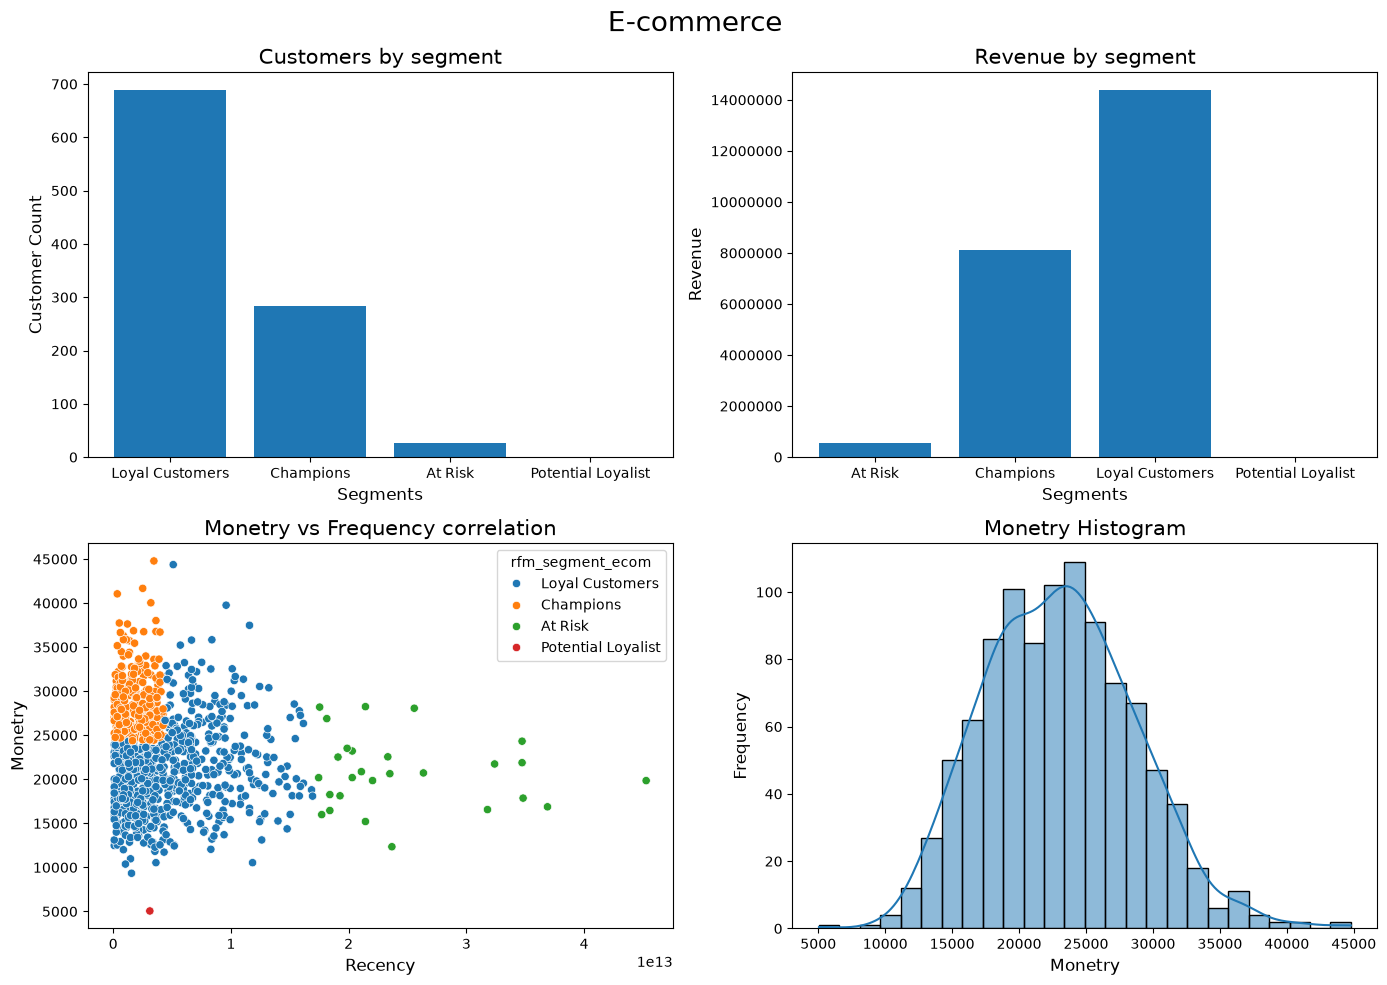

In [27]:
                                                    # VISUALIZATION for ecom
# count of customers in each segment
fig, ax = plt.subplots(2,2, figsize = (14,10))
ax[0,0].bar(rfm.rfm_segment_ecom.value_counts().index, rfm.rfm_segment_ecom.value_counts())
ax[0,0].set_title('Customers by segment', fontsize=15)
ax[0,0].set_ylabel('Customer Count', fontsize=12.5)
ax[0,0].set_xlabel('Segments', fontsize=12.5)

# revenue by each segment
ax[0,1].bar(rfm.groupby('rfm_segment_ecom')['Monetry'].sum().index, rfm.groupby('rfm_segment_ecom')['Monetry'].sum())
ax[0,1].set_title('Revenue by segment', fontsize=15)
ax[0,1].set_ylabel('Revenue', fontsize=12.5)
ax[0,1].set_xlabel('Segments', fontsize=12.5)
ax[0,1].ticklabel_format(style='plain', axis='y')

# scatterplot between recency and monetry
sns.scatterplot(data=rfm, x='Recency', y='Monetry', ax=ax[1,0],hue=rfm.rfm_segment_ecom ,color=['red','blue','yellow','magenta'])
ax[1,0].set_title('Monetry vs Frequency correlation', fontsize=15)
ax[1,0].set_ylabel('Monetry', fontsize=12.5)
ax[1,0].set_xlabel('Recency', fontsize=12.5)

# sns.histplot(data=rfm, x='Monetry', kde=True)
sns.histplot(data=rfm, x='Monetry', kde=True, ax=ax[1,1])
ax[1,1].set_title('Monetry Histogram', fontsize=15)
ax[1,1].set_ylabel('Frequency', fontsize=12.5)
ax[1,1].set_xlabel('Monetry', fontsize=12.5)


plt.suptitle('E-commerce', fontsize=20)
plt.tight_layout()
plt.show()

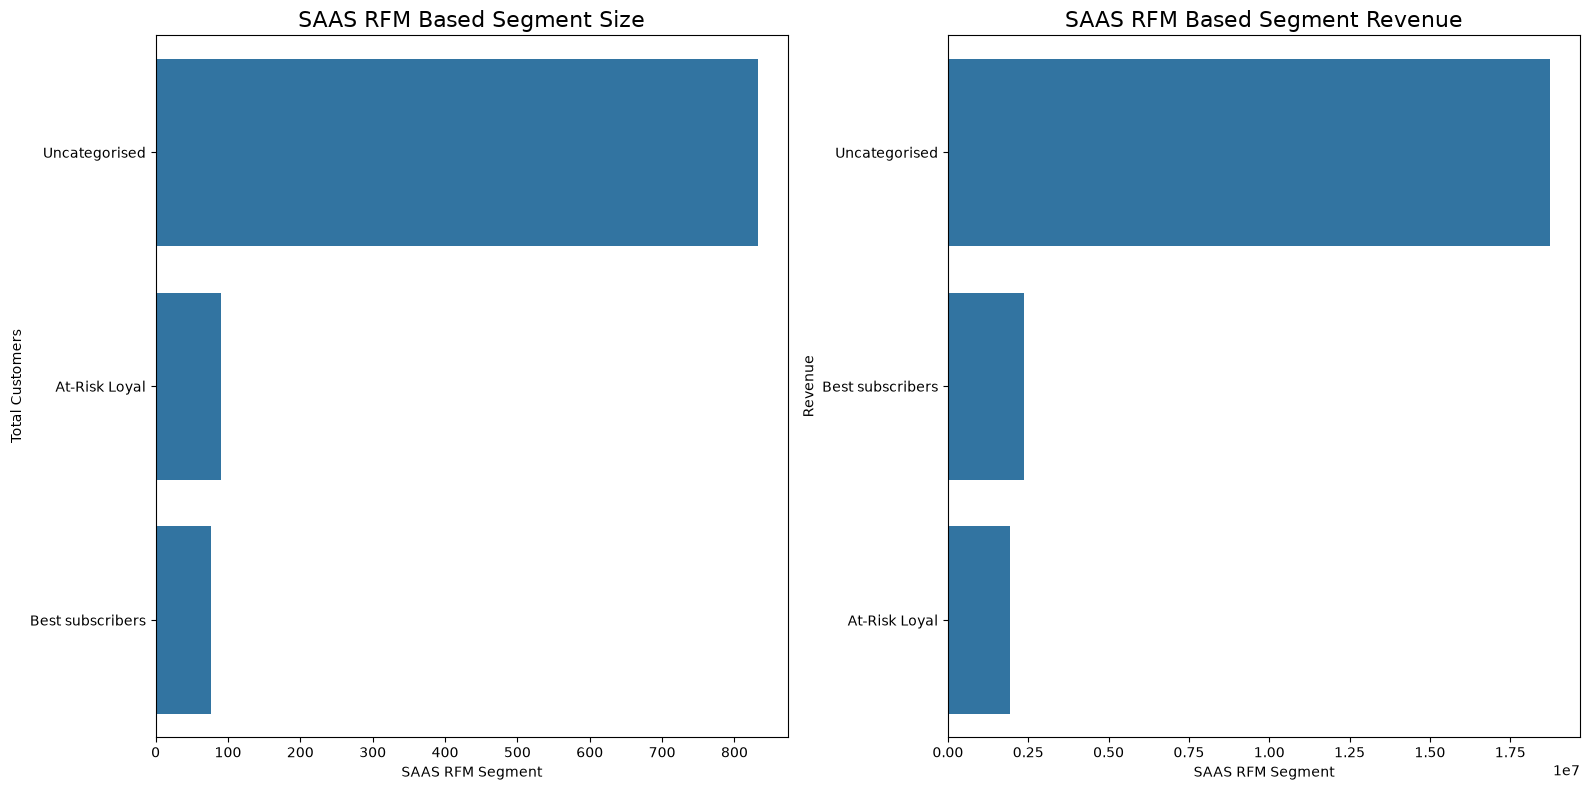

In [29]:
fig, ax = plt.subplots(1,2, figsize=[16,8])

# rfm.rfm_segment_SAAS.unique()
SAAS_rfm = rfm.rfm_segment_SAAS.value_counts().reset_index()
sns.barplot(data=SAAS_rfm, y="rfm_segment_SAAS", x="count", ax=ax[0], orient='h')
ax[0].set_xlabel("SAAS RFM Segment")
ax[0].set_ylabel("Total Customers")
ax[0].set_title("SAAS RFM Based Segment Size", fontsize = 16)

SAAS_rfm_monetry = rfm.groupby("rfm_segment_SAAS")['Monetry'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=SAAS_rfm_monetry, y="rfm_segment_SAAS", x="Monetry", ax=ax[1])
ax[1].set_xlabel("SAAS RFM Segment")
ax[1].set_ylabel("Revenue")
ax[1].set_title('SAAS RFM Based Segment Revenue', fontsize = 16)

plt.tight_layout()
# plt.suptitle('SAAS RFM Segmentation', fontsize=20)
plt.show()